# Современные расписания learning rate: WSD и Schedule-Free

**Доклад по курсу ТИНС.** ✍️ ФИО, группа

**Идея.** Стандартное расписание — warmup + cosine (в РК1, вариант 6, оно дало лучший результат). Его минус: форма косинуса зависит от длины обучения $T$, поэтому $T$ нужно знать заранее. Если захотелось учить дольше или получить модели для нескольких бюджетов, каждый раз приходится обучать заново.

Два современных решения:
- **WSD (Warmup–Stable–Decay):** разогрев → долгий постоянный lr → короткое затухание в конце. Стабильная фаза не зависит от $T$, поэтому затухание можно запустить из любой сохранённой точки.
- **Schedule-Free** (Defazio et al., 2024): lr постоянный, а шум SGD гасится усреднением весов.

**Эксперимент:** та же сеть и данные, что в РК1 (MLP 784→64→10 на подвыборке MNIST, SGD, 5 seed).

In [1]:
import os, math, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

SEEDS = [60, 61, 62, 63, 64]
EPOCHS, BATCH, HIDDEN = 20, 64, 64

path = 'data/mnist.npz'
if not os.path.exists(path):
    os.makedirs('data', exist_ok=True)
    urllib.request.urlretrieve('https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz', path)
d = np.load(path)
rng = np.random.default_rng(0)
i, j = rng.permutation(60000), rng.permutation(10000)[:2000]
X, Xt = d['x_train'].reshape(-1, 784) / 255, d['x_test'].reshape(-1, 784) / 255
Xtr, ytr = X[i[:6000]], d['y_train'][i[:6000]]
Xva, yva = X[i[6000:8000]], d['y_train'][i[6000:8000]]
Xte, yte = Xt[j], d['y_test'][j]
STEPS = math.ceil(len(Xtr) / BATCH)      # шагов за эпоху (94)
T_MAX = EPOCHS * STEPS                    # шагов за 20 эпох (1880)
os.makedirs('figs', exist_ok=True)        # сюда сохраняются графики для презентации

## 1. Модель и обучение

Сеть и backprop — как в РК1. Добавлен один режим: **Schedule-Free SGD**. В нём хранятся две копии весов:
- $z$ — «быстрые» веса обычного SGD: $z \leftarrow z - \eta\,\nabla L(y)$;
- $x$ — их взвешенное среднее: $x \leftarrow (1-c)\,x + c\,z$, где $c_t = \eta_t^2 / \sum_{s \le t}\eta_s^2$;
- градиент считается в точке $y = (1-\beta)\,z + \beta\,x$, $\beta = 0.9$.

Предсказания и оценка делаются на **усреднённых** весах $x$.

In [2]:
def init(seed):
    r = np.random.default_rng(seed)
    return [r.normal(0, np.sqrt(2 / 784), (784, HIDDEN)), np.zeros(HIDDEN),
            r.normal(0, np.sqrt(1 / HIDDEN), (HIDDEN, 10)), np.zeros(10)]

def forward(P, X):
    W1, b1, W2, b2 = P
    z1 = X @ W1 + b1
    h = np.maximum(z1, 0)
    z2 = h @ W2 + b2
    z2 = z2 - z2.max(1, keepdims=True)
    return z1, h, z2 - np.log(np.exp(z2).sum(1, keepdims=True))

def loss_acc(P, X, y):
    logp = forward(P, X)[2]
    return -logp[np.arange(len(y)), y].mean(), (logp.argmax(1) == y).mean()

def grad(P, X, y):                                  # loss и градиенты (backprop)
    W1, b1, W2, b2 = P
    z1, h, logp = forward(P, X)
    loss = -logp[np.arange(len(y)), y].mean()
    d2 = np.exp(logp); d2[np.arange(len(y)), y] -= 1; d2 /= len(y)
    d1 = (d2 @ W2.T) * (z1 > 0)
    return loss, [X.T @ d1, d1.sum(0), h.T @ d2, d2.sum(0)]

def train(sched, seed, epochs=EPOCHS, sf_beta=None, start=None, t0=0, save_at=()):
    """sched(t) -> lr на шаге t.  sf_beta=None — обычный SGD, число — Schedule-Free SGD.
    start/t0 — продолжить с сохранённых весов с шага t0;  save_at — эпохи, в которые сохранить веса."""
    z = init(seed) if start is None else [p.copy() for p in start]
    x, wsum = [p.copy() for p in z], 0.0
    order = np.random.default_rng(1)
    for _ in range(t0 // STEPS):                    # тот же порядок батчей, что и без остановки
        order.permutation(len(Xtr))
    H = {'loss': [], 'lr': [], 'val_acc': [], 'saved': {}}
    t = t0
    with np.errstate(all='ignore'):
        for ep in range(epochs):
            perm = order.permutation(len(Xtr))
            for k in range(STEPS):
                b = perm[k * BATCH:(k + 1) * BATCH]
                lr = sched(t)
                if sf_beta is None:
                    loss, g = grad(z, Xtr[b], ytr[b])
                else:
                    y_ = [(1 - sf_beta) * zz + sf_beta * xx for zz, xx in zip(z, x)]
                    loss, g = grad(y_, Xtr[b], ytr[b])
                for p, gg in zip(z, g):
                    p -= lr * gg
                if sf_beta is not None:             # обновляем среднее x
                    wsum += lr ** 2
                    c = lr ** 2 / wsum
                    for xx, zz in zip(x, z):
                        xx += c * (zz - xx)
                H['loss'].append(loss); H['lr'].append(lr); t += 1
            ev = z if sf_beta is None else x
            H['val_acc'].append(loss_acc(ev, Xva, yva)[1])
            if t0 // STEPS + ep + 1 in save_at:
                H['saved'][t0 // STEPS + ep + 1] = [p.copy() for p in z]
        H['test_loss'], H['test_acc'] = loss_acc(z if sf_beta is None else x, Xte, yte)
    return H

def summary(res, base):
    rows = []
    b = np.array([r['test_acc'] for r in res[base]])
    for name, runs in res.items():
        a = np.array([r['test_acc'] for r in runs])
        rows.append({'метод': name, 'test acc': a.mean(),
                     'CI95 ±': stats.t.ppf(0.975, 4) * a.std(ddof=1) / np.sqrt(5),
                     'test loss': np.mean([r['test_loss'] for r in runs]),
                     'Δ к ' + base: (a - b).mean(),
                     'p (парный t-тест)': stats.ttest_rel(a, b).pvalue if name != base else np.nan})
    return pd.DataFrame(rows).set_index('метод').round(4)

## 2. Расписания

lr меняется раз в 10 шагов. Разогрев у всех одинаковый: первые 10% шагов lr линейно растёт от $lr_0/100$ до $lr_0$.
- **warmup + cosine** (лучшее из РК1): после разогрева $lr = lr_{min} + \frac{lr_0 - lr_{min}}{2}\left(1 + \cos\frac{\pi (t - T_{warm})}{T - T_{warm}}\right)$ — **зависит от $T$ на каждом шаге**.
- **WSD:** после разогрева $lr = lr_0$, а последние 20% шагов линейно падает до 0. От $T$ зависит только начало затухания.
- **Schedule-Free:** после разогрева $lr$ постоянный. Ему нужен шаг побольше ($lr_0 = 3$ вместо 1), потому что усреднение «тормозит» движение весов.

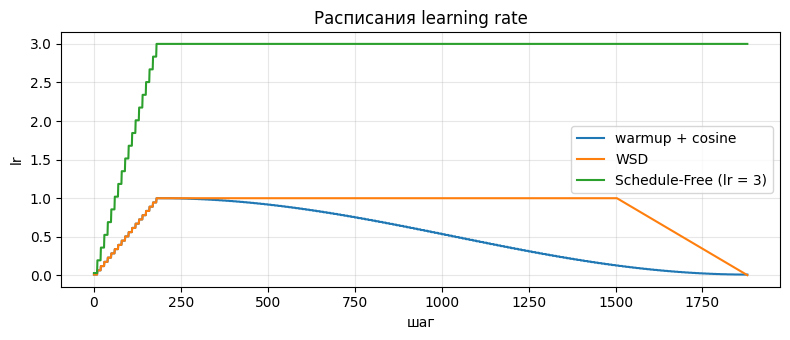

In [3]:
LR0, LR_SF, N = 1.0, 3.0, 10
T_WARM = int(0.1 * T_MAX) // N * N                 # 180 шагов разогрева

def q(t):
    return t // N * N                                 # lr обновляется раз в N шагов

def warmup(t, lr0):
    return lr0 / 100 + (lr0 - lr0 / 100) * q(t) / T_WARM

def warm_cos(T, lr0=LR0):
    def f(t):
        if q(t) < T_WARM:
            return warmup(t, lr0)
        return lr0 / 100 + (lr0 - lr0 / 100) / 2 * (1 + math.cos(math.pi * (q(t) - T_WARM) / (T - T_WARM + 1)))
    return f

def wsd(T, lr0=LR0, decay=0.2):
    T_dec = int(decay * T)
    def f(t):
        if q(t) < T_WARM:
            return warmup(t, lr0)
        if t < T - T_dec:
            return lr0                                # стабильная фаза — не зависит от T
        return lr0 * (T - t) / T_dec                  # затухание до 0
    return f

def sf_sched(lr0=LR_SF):
    return lambda t: warmup(t, lr0) if q(t) < T_WARM else lr0

steps = np.arange(T_MAX)
plt.figure(figsize=(8, 3.5))
for name, f in {'warmup + cosine': warm_cos(T_MAX), 'WSD': wsd(T_MAX),
                'Schedule-Free (lr = 3)': sf_sched()}.items():
    plt.plot(steps, [f(t) for t in steps], label=name)
plt.xlabel('шаг'); plt.ylabel('lr'); plt.title('Расписания learning rate'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('figs/schedules.png', dpi=150); plt.show()

## 3. Эксперимент 1: сравнение на 20 эпохах (5 seed)

In [4]:
res = {'warmup + cosine': [train(warm_cos(T_MAX), s) for s in SEEDS],
       'WSD':             [train(wsd(T_MAX), s) for s in SEEDS],
       'Schedule-Free':   [train(sf_sched(), s, sf_beta=0.9) for s in SEEDS]}
display(summary(res, base='warmup + cosine'))

,test acc,CI95 ±,test loss,Δ к warmup + cosine,p (парный t-тест)
метод,,,,,
warmup + cosine,0.9557,0.0049,0.1679,0.0000,NaN
WSD,0.9571,0.0039,0.1768,0.0014,0.0870
Schedule-Free,0.9536,0.0036,0.2658,-0.0021,0.1706


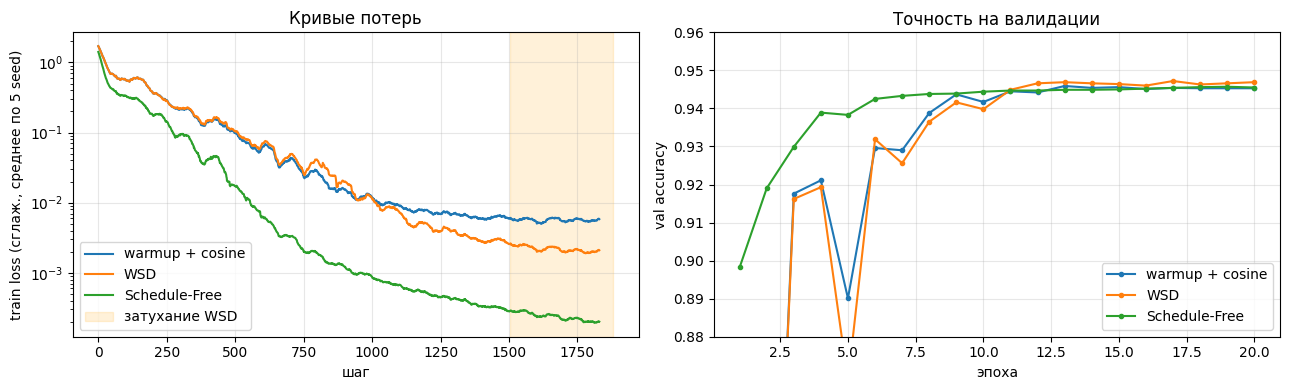

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, runs in res.items():
    L = np.mean([np.convolve(r['loss'], np.ones(50) / 50, mode='valid') for r in runs], 0)
    ax[0].plot(L, label=name)
    ax[1].plot(range(1, EPOCHS + 1), np.mean([r['val_acc'] for r in runs], 0), marker='o', ms=3, label=name)
ax[0].axvspan(T_MAX * 0.8, T_MAX, color='orange', alpha=0.15, label='затухание WSD')
ax[0].set(yscale='log', xlabel='шаг', ylabel='train loss (сглаж., среднее по 5 seed)', title='Кривые потерь')
ax[1].set(xlabel='эпоха', ylabel='val accuracy', ylim=(0.88, 0.96), title='Точность на валидации')
for a in ax:
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('figs/compare.png', dpi=150); plt.show()

**Вывод.** На 20 эпохах все три метода дают почти одинаковую точность. WSD не хуже cosine (разница в пределах разброса, p ≈ 0.09), Schedule-Free в конце немного уступает. Зато на первых ~10 эпохах у Schedule-Free самая высокая точность на валидации: его усреднённые веса хороши в любой момент, без затухания lr. Для маленькой сети точность почти насыщается, поэтому главное преимущество новых методов не в точности, а в **гибкости** (эксперимент 2).

## 4. Эксперимент 2: несколько бюджетов обучения (5, 10, 15, 20 эпох)

Задача: получить хорошие модели для четырёх длин обучения.
- **Cosine:** форма зависит от $T$, поэтому нужно 4 **отдельных** обучения: 5 + 10 + 15 + 20 = **50 эпох**.
- **WSD:** **один** основной прогон с постоянным lr и сохранением весов. Для бюджета $B$ берём веса на эпохе $0.8B$ и делаем короткое затухание на $0.2B$ эпох. Основной прогон нужен только до эпохи $0.8 \cdot 20 = 16$, итого 16 + (1 + 2 + 3 + 4) = **26 эпох**.

In [6]:
BUDGETS = [5, 10, 15, 20]
anytime = {'cosine (отдельные обучения)': {}, 'WSD (один прогон + затухания)': {}}

for B in BUDGETS:                                   # cosine: отдельный прогон на каждый бюджет
    anytime['cosine (отдельные обучения)'][B] = [train(warm_cos(B * STEPS), s, epochs=B)['test_acc'] for s in SEEDS]

for B in BUDGETS:
    anytime['WSD (один прогон + затухания)'][B] = []
for s in SEEDS:                                     # WSD: один длинный прогон с постоянным lr
    main = train(wsd(10 ** 9), s, epochs=16, save_at=[int(0.8 * B) for B in BUDGETS])
    for B in BUDGETS:                               # затухание из сохранённой точки
        e0 = int(0.8 * B)
        cd = train(wsd(B * STEPS), s, epochs=B - e0, start=main['saved'][e0], t0=e0 * STEPS)
        anytime['WSD (один прогон + затухания)'][B].append(cd['test_acc'])

tab = pd.DataFrame({m: {B: f'{np.mean(v):.4f} ± {np.std(v, ddof=1):.4f}' for B, v in r.items()}
                    for m, r in anytime.items()}).rename_axis('бюджет, эпох')
display(tab)
MAIN = int(0.8 * max(BUDGETS))                      # длина основного прогона WSD
print('Вычислений: cosine', sum(BUDGETS), 'эпох; WSD', MAIN + sum(B - int(0.8 * B) for B in BUDGETS), 'эпох')

,cosine (отдельные обучения),WSD (один прогон + затухания)
"бюджет, эпох",,
5,0.9497 ± 0.0055,0.9508 ± 0.0027
10,0.9534 ± 0.0036,0.9554 ± 0.0040
15,0.9557 ± 0.0047,0.9572 ± 0.0026
20,0.9557 ± 0.0040,0.9571 ± 0.0031


Вычислений: cosine 50 эпох; WSD 26 эпох


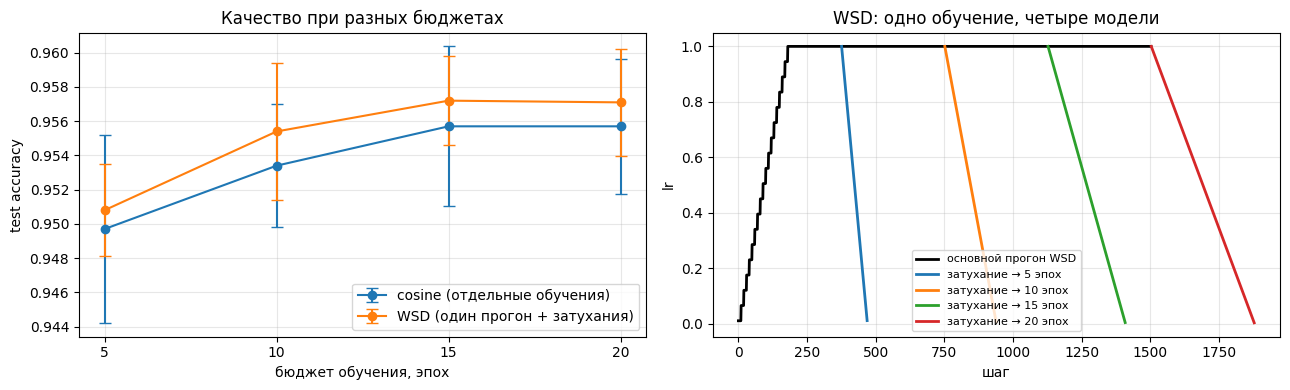

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for m, r in anytime.items():
    ax[0].errorbar(BUDGETS, [np.mean(r[B]) for B in BUDGETS], yerr=[np.std(r[B], ddof=1) for B in BUDGETS],
                   marker='o', capsize=4, label=m)
ax[0].set(xlabel='бюджет обучения, эпох', ylabel='test accuracy', title='Качество при разных бюджетах')
ax[0].set_xticks(BUDGETS); ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(range(16 * STEPS), [wsd(10 ** 9)(t) for t in range(16 * STEPS)], 'k', lw=2, label='основной прогон WSD')
for B in BUDGETS:
    t = np.arange(int(0.8 * B) * STEPS, B * STEPS)
    ax[1].plot(t, [wsd(B * STEPS)(x) for x in t], lw=2, label=f'затухание → {B} эпох')
ax[1].set(xlabel='шаг', ylabel='lr', title='WSD: одно обучение, четыре модели'); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig('figs/anytime.png', dpi=150); plt.show()

**Вывод.** При каждом бюджете WSD даёт точность на уровне отдельно обученного cosine, но все четыре модели получены из **одного** обучения: 26 эпох вычислений вместо 50 (почти вдвое меньше). Если позже понадобится учить дольше, основной прогон WSD можно просто продолжить. С cosine так не получится: его lr уже упал почти до нуля.

## 5. Эксперимент 3: то же на задаче побольше (CIFAR-10, GPU)

На MNIST точность быстро насыщается, поэтому разница между методами получилась в пределах разброса. Поэтому тот же опыт повторён на CIFAR-10: небольшой ResNet с BatchNorm, SGD + momentum 0.9, батч 512, пиковый lr 0.2, аугментации flip + crop, 3 seed. Код — `wsd_experiment.py` (PyTorch, ~1 час на RTX 4060), результаты в `results/`.

Сравниваются бюджеты 10, 20, 40 эпох:
- **cosine(B)** — отдельное обучение под каждый бюджет;
- **cosine(Tmax)→B** — cosine, рассчитанный на 40 эпох, но остановленный раньше;
- **const** — постоянный lr без затухания;
- **WSD** — один прогон с постоянным lr + затухание на последние 20% бюджета;
- **Schedule-Free**.

| стратегия | 10 эпох | 20 эпох | 40 эпох |
|---|---|---|---|
| cosine(B) | 87.40 ± 0.42 | 91.12 ± 0.10 | 93.11 ± 0.14 |
| cosine(Tmax)→B | 83.77 ± 0.68 | 87.79 ± 0.56 | 93.11 ± 0.14 |
| const | 81.92 ± 0.72 | 84.51 ± 0.40 | 85.65 ± 0.19 |
| **WSD** | **88.80 ± 0.33** | **92.19 ± 0.20** | **93.43 ± 0.16** |
| Schedule-Free | 86.22 ± 0.95 | 90.25 ± 0.30 | 91.59 ± 0.11 |

Test accuracy, %, среднее ± std по 3 seed. Вычислений на все три бюджета: cosine(B) — 70 эпох, WSD — 46, Schedule-Free — 40.

![](results/budgets.png)
![](results/curves.png)

**Вывод.** На CIFAR-10 разница видна: WSD на всех бюджетах не хуже cosine, а на 10 и 20 эпохах выше на 1–1.4%, при этом вычислений нужно 46 эпох вместо 70. Cosine, рассчитанный на 40 эпох и остановленный раньше, теряет 3–4%, а постоянный lr без затухания застревает около 85%. Основной прирост даёт именно затухание в конце. Schedule-Free снова лучший в начале, но к концу уступает ~1.5% (его lr не подбирался).

## 6. Выводы

1. Warmup + cosine — хорошее расписание, но его форма привязана к длине обучения $T$.
2. **WSD** по качеству не уступает cosine, а на CIFAR-10 на коротких бюджетах даже выше на 1–1.4%. Главный плюс: из одного прогона можно получить модели для любых бюджетов и продолжать обучение. Поэтому WSD используют при обучении больших языковых моделей.
3. **Schedule-Free** обходится вовсе без расписания (только постоянный lr и усреднение весов). На нашей задаче он немного уступил по точности, нужен больший lr и дополнительная копия весов.
4. На MNIST разница в точности мала, потому что точность быстро насыщается. На задаче посложнее (CIFAR-10) разница видна явно, и WSD выигрывает и по точности, и по вычислениям (46 эпох вместо 70).